# 02 — Exploratory Data Analysis (EDA)

Studio Proyek 2 · Klasifikasi 5 jenis sampah (IF25-40401)

Tujuan notebook ini: memahami karakteristik dataset `train/` sebelum preprocessing, terutama hal-hal yang memengaruhi Macro-F1.

## 1. Setup

Konstanta sama dengan `01_data_loading.ipynb`, lalu kumpulkan daftar gambar per kelas (sudah dipastikan valid di notebook 01).

In [2]:
import csv
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image
from torchvision import models, transforms

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)

DATA_DIR = ROOT / "train"
CLASSES = ["botol_plastik", "gelas_plastik", "kertas_kardus", "saset_kemasan", "styrofoam"]
IMG_EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
SEED = 42

files_by_class = {
    c: sorted(p for p in (DATA_DIR / c).iterdir() if p.suffix.lower() in IMG_EXTS) for c in CLASSES
}
print({c: len(fs) for c, fs in files_by_class.items()})

{'botol_plastik': 523, 'gelas_plastik': 521, 'kertas_kardus': 365, 'saset_kemasan': 673, 'styrofoam': 671}


## 2. Distribusi kelas

Metrik penilaian adalah **Macro-F1**: kelima kelas berbobot sama, jadi kelas dengan data paling sedikit tetap menyumbang 20% skor.
Hitung proporsi tiap kelas dan rasio imbalance (kelas terbesar / terkecil).

botol_plastik     523  (19.0%)
gelas_plastik     521  (18.9%)
kertas_kardus     365  (13.3%)
saset_kemasan     673  (24.4%)
styrofoam         671  (24.4%)
TOTAL            2753

rasio imbalance (terbesar / terkecil): 1.84x


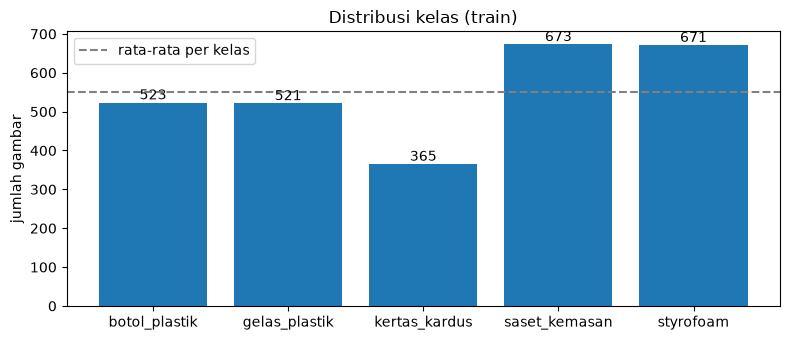

In [3]:
counts = {c: len(fs) for c, fs in files_by_class.items()}
total = sum(counts.values())

for c, n in counts.items():
    print(f"{c:<15} {n:>5}  ({n / total:.1%})")
print(f"{'TOTAL':<15} {total:>5}")

ratio = max(counts.values()) / min(counts.values())
print(f"\nrasio imbalance (terbesar / terkecil): {ratio:.2f}x")

fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.bar(counts.keys(), counts.values())
ax.bar_label(bars)
ax.axhline(total / len(CLASSES), ls="--", c="gray", label="rata-rata per kelas")
ax.set_ylabel("jumlah gambar")
ax.set_title("Distribusi kelas (train)")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Ukuran & rasio aspek gambar

Gambar dikumpulkan dari web, jadi ukurannya bervariasi. Hasil di sini menentukan resolusi input dan strategi resize/crop saat preprocessing:
gambar yang terlalu kecil akan pecah saat diperbesar, dan rasio aspek yang ekstrem bisa terpotong oleh `CenterCrop`.

kelas           lebar med tinggi med sisi pendek min
botol_plastik         800        683             188
gelas_plastik         800        800             178
kertas_kardus         800        683             150
saset_kemasan         819        768             154
styrofoam             800        700             150

lebar  min/median/max : 150 / 800 / 1024
tinggi min/median/max : 150 / 753 / 1024
sisi pendek < 224 px  : 33 gambar (1.2%)
rasio aspek ekstrem (<0.5 atau >2): 23 gambar


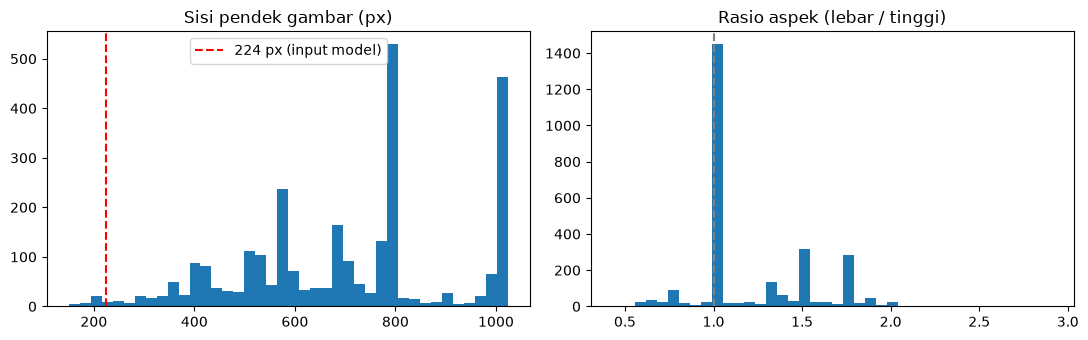

In [4]:
sizes = {}  # kelas -> array [n, 2] berisi (lebar, tinggi)
for c, fs in files_by_class.items():
    dims = []
    for p in fs:
        with Image.open(p) as im:
            dims.append(im.size)
    sizes[c] = np.array(dims)

all_sizes = np.concatenate(list(sizes.values()))
w, h = all_sizes[:, 0], all_sizes[:, 1]
aspect = w / h
short_side = np.minimum(w, h)

print(f"{'kelas':<15} {'lebar med':>9} {'tinggi med':>10} {'sisi pendek min':>15}")
for c, s in sizes.items():
    print(f"{c:<15} {int(np.median(s[:, 0])):>9} {int(np.median(s[:, 1])):>10} {s.min(axis=1).min():>15}")

print(f"\nlebar  min/median/max : {w.min()} / {int(np.median(w))} / {w.max()}")
print(f"tinggi min/median/max : {h.min()} / {int(np.median(h))} / {h.max()}")
print(f"sisi pendek < 224 px  : {(short_side < 224).sum()} gambar ({(short_side < 224).mean():.1%})")
print(f"rasio aspek ekstrem (<0.5 atau >2): {((aspect < 0.5) | (aspect > 2)).sum()} gambar")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(short_side, bins=40)
axes[0].axvline(224, ls="--", c="red", label="224 px (input model)")
axes[0].set_title("Sisi pendek gambar (px)")
axes[0].legend()
axes[1].hist(aspect, bins=40)
axes[1].axvline(1, ls="--", c="gray")
axes[1].set_title("Rasio aspek (lebar / tinggi)")
plt.tight_layout()
plt.show()

**Temuan:**
- Median sisi pendek ±700–800 px; hanya 33 gambar (1,2%) < 224 px → input 224 px aman, resolusi lebih tinggi (256–320) bisa dicoba.
- Ukuran tidak berbeda mencolok antar kelas → model tidak bisa menebak kelas dari ukuran.
- Mayoritas persegi; sisanya landscape 4:3, 3:2, 16:9; hanya 23 gambar dengan rasio di luar 0,5–2.
- `CenterCrop` memotong ±44% lebar gambar 16:9 → cek di contoh gambar apakah objek ikut terpotong.

## 4. Contoh gambar per kelas

- (a) 6 gambar acak per kelas → lihat variasi isi tiap kelas dan kemungkinan label salah.
- (b) Gambar paling lebar → kotak merah = area yang tersisa setelah `Resize(256)` + `CenterCrop(224)`.

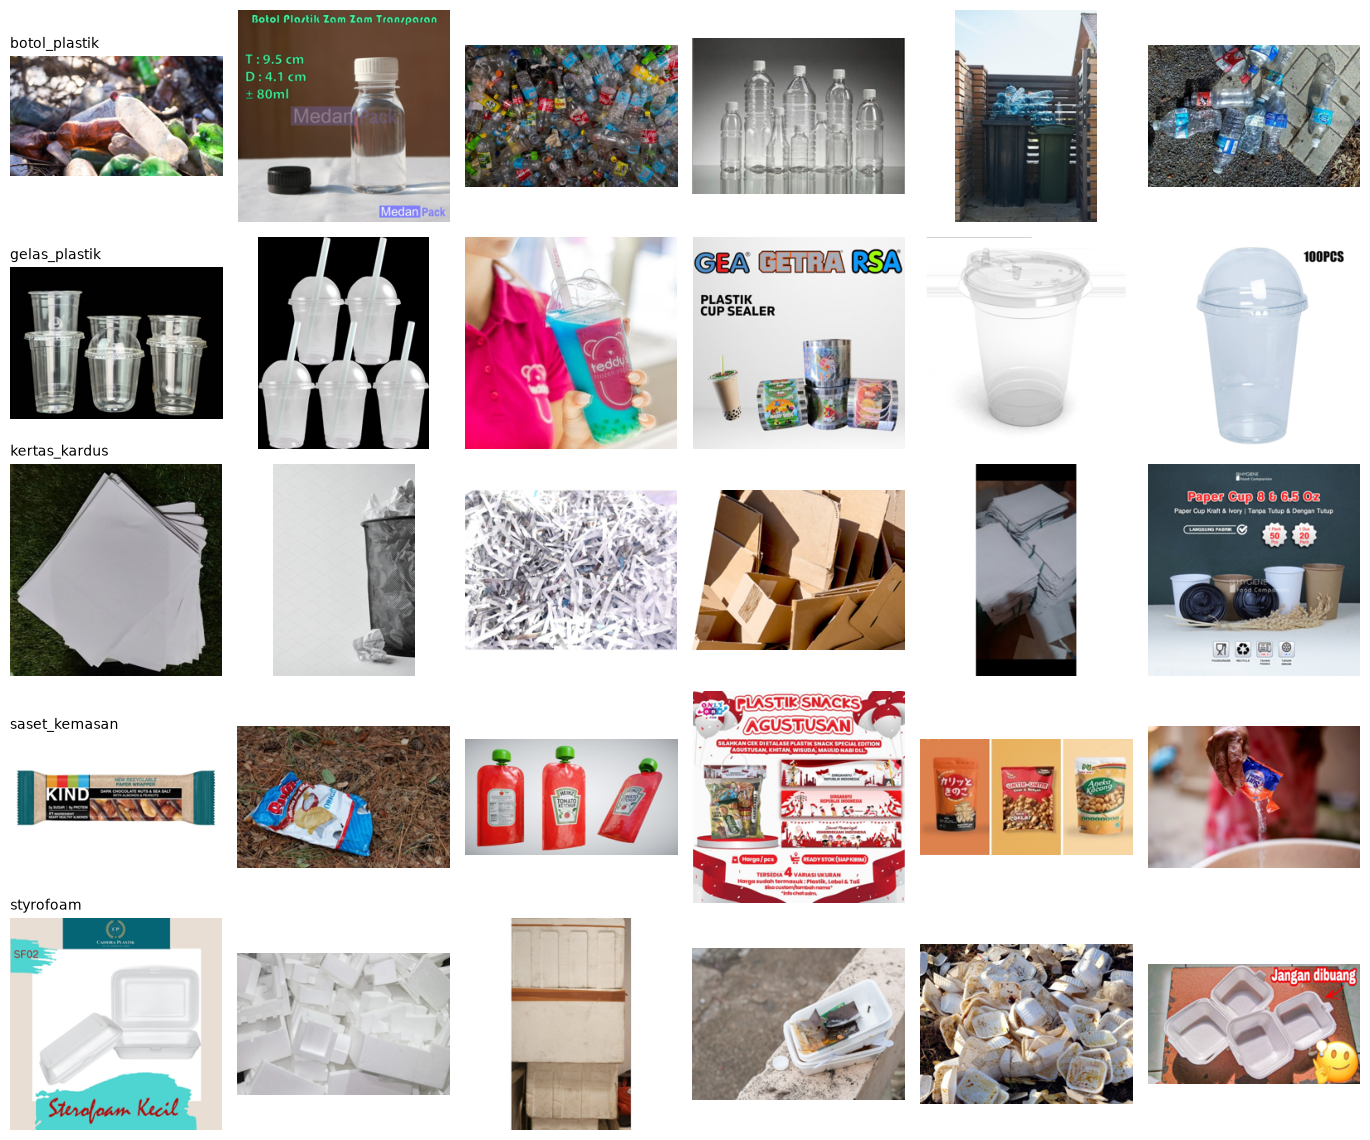

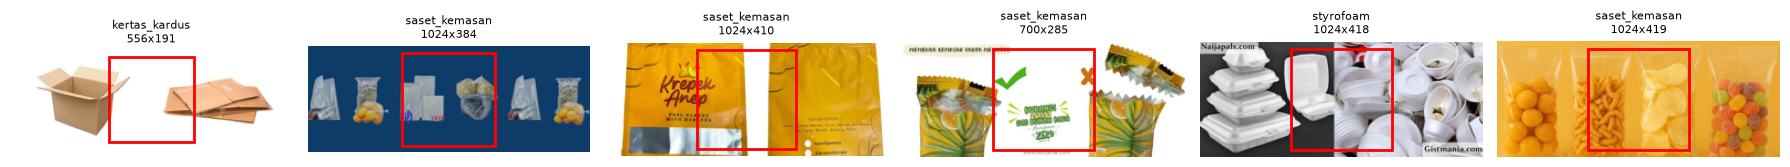

In [5]:
import random

from matplotlib.patches import Rectangle


def thumb(path, max_side=256):
    """Muat gambar sebagai thumbnail RGB supaya plot hemat memori."""
    with Image.open(path) as im:
        im = im.convert("RGB")
        im.thumbnail((max_side, max_side))
        return im


# (a) contoh acak per kelas
N_SHOW = 6
rng = random.Random(SEED)
fig, axes = plt.subplots(len(CLASSES), N_SHOW, figsize=(2.3 * N_SHOW, 2.3 * len(CLASSES)))
for r, c in enumerate(CLASSES):
    for col, p in enumerate(rng.sample(files_by_class[c], N_SHOW)):
        axes[r, col].imshow(thumb(p))
        axes[r, col].axis("off")
    axes[r, 0].set_title(c, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

# (b) gambar paling lebar + area yang tersisa setelah CenterCrop
all_files = [p for fs in files_by_class.values() for p in fs]
widest = [all_files[i] for i in np.argsort(aspect)[::-1][:6]]
fig, axes = plt.subplots(1, 6, figsize=(18, 3))
for ax, p in zip(axes, widest):
    with Image.open(p) as im:
        W, H = im.size
    ax.imshow(thumb(p), extent=(0, W, H, 0))  # extent: koordinat tetap dalam piksel asli
    side = min(W, H) * 224 / 256  # sisi kotak crop dalam piksel asli
    ax.add_patch(Rectangle(((W - side) / 2, (H - side) / 2), side, side, fill=False, ec="red", lw=2))
    ax.set_title(f"{p.parent.name}\n{W}x{H}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Temuan:**
- Banyak gambar katalog/iklan (teks, logo, watermark, banner), bukan foto sampah nyata → domain campuran, model bisa belajar dari teks/latar.
- Satu gambar bisa berisi banyak objek (tumpukan botol, beberapa gelas/saset).
- Label ambigu sesuai definisi kelas: gelas kertas masuk `kertas_kardus` (mirip gelas plastik/styrofoam), gambar mesin sealer cup di `gelas_plastik` (kemungkinan noise).
- Kelas `saset_kemasan` paling beragam (bar cokelat, pouch saus, poster promosi).
- Gambar sangat lebar: `CenterCrop` membuang objek di pinggir (mis. kardus 556×191, deretan saset).

**Implikasi untuk preprocessing:**
- Pertimbangkan resize ke persegi tanpa crop untuk validasi, atau `scale` minimum `RandomResizedCrop` lebih besar.
- Augmentasi warna & crop lebih kuat → model tidak bergantung pada teks/latar.

## 5. Duplikat & near-duplicate

- Duplikat beda kelas = label bertentangan (noise).
- Pakai *difference hash* (dHash 256-bit): gambar dikecilkan ke 17×16 grayscale, bandingkan piksel bertetangga. Jarak Hamming ≤ 30 bit dianggap near-duplicate.
- dHash 64-bit sempat dicoba, tapi banyak salah deteksi (mis. botol vs kardus) karena terlalu kasar.

pasangan near-duplicate (jarak <= 30): 16
  - kelas sama  : 16
  - beda kelas  : 0  (label bertentangan)
gambar yang terlibat: 27


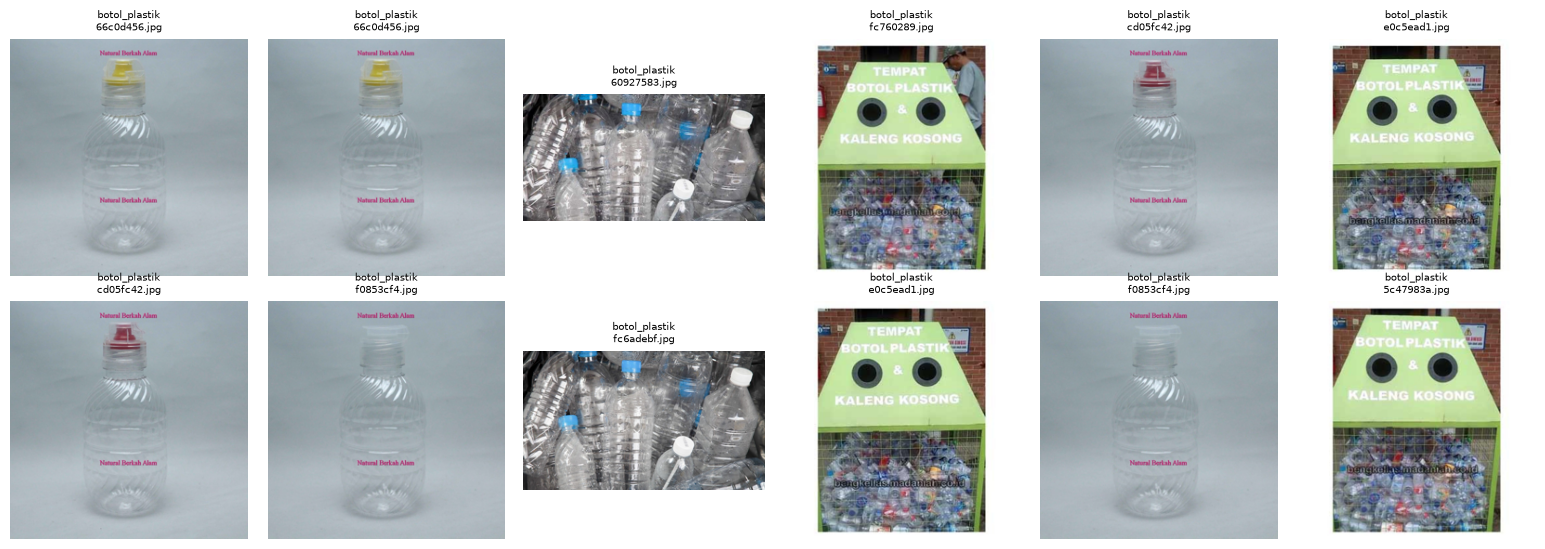

In [6]:
def dhash(path, size=16):
    """256-bit difference hash: tahan terhadap resize, kompresi, dan sedikit perubahan warna."""
    with Image.open(path) as im:
        g = np.asarray(im.convert("L").resize((size + 1, size), Image.LANCZOS), dtype=np.int16)
    return np.packbits((g[:, 1:] > g[:, :-1]).flatten())  # 32 byte


labels = np.array([c for c, fs in files_by_class.items() for _ in fs])
hashes = np.stack([dhash(p) for p in all_files])  # [N, 32] uint8

# Jarak Hamming semua pasangan: XOR per byte, lalu hitung bit 1 lewat lookup table
popcount = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint16)
dist = np.zeros((len(all_files), len(all_files)), dtype=np.uint16)
for b in range(hashes.shape[1]):
    dist += popcount[hashes[:, b][:, None] ^ hashes[:, b][None, :]]

MAX_DIST = 30  # dari 256 bit; dicek manual: <= 30 semuanya duplikat asli, > 40 mulai salah deteksi
i_idx, j_idx = np.where(np.triu(dist <= MAX_DIST, k=1))
pairs = list(zip(i_idx, j_idx))
cross = [(i, j) for i, j in pairs if labels[i] != labels[j]]

print(f"pasangan near-duplicate (jarak <= {MAX_DIST}): {len(pairs)}")
print(f"  - kelas sama  : {len(pairs) - len(cross)}")
print(f"  - beda kelas  : {len(cross)}  (label bertentangan)")
print(f"gambar yang terlibat: {len(set(i_idx) | set(j_idx))}")

# Tampilkan contoh pasangan, utamakan yang beda kelas
show = (cross + [p for p in pairs if p not in cross])[:6]
if show:
    fig, axes = plt.subplots(2, len(show), figsize=(2.6 * len(show), 5.5), squeeze=False)
    for col, (i, j) in enumerate(show):
        for row, k in enumerate((i, j)):
            axes[row, col].imshow(thumb(all_files[k]))
            axes[row, col].set_title(f"{labels[k]}\n{all_files[k].name[-12:]}", fontsize=7)
            axes[row, col].axis("off")
    plt.tight_layout()
    plt.show()

**Temuan:**
- 16 pasangan near-duplicate (27 gambar, ±1% data), semuanya kelas sama → tidak ada label bertentangan.
- Bentuknya: foto produk yang sama dengan variasi warna tutup, crop, atau watermark.
- 2 pasangan terbelah di `my_train`/`my_val` saat ini → skor lokal sedikit optimis; tangani di preprocessing (satu grup duplikat di split yang sama).

## 6. Statistik warna per kelas

- Cek apakah kelas bisa ditebak hanya dari warna/kecerahan (mis. styrofoam putih, kardus cokelat) → *shortcut* yang membuat model rapuh.
- Tiap gambar dikecilkan ke 64×64, lalu dihitung rata-rata R, G, B, kecerahan, dan saturasi.
- Uji sederhana: klasifikasi *nearest centroid* hanya dari 5 fitur warna ini. Makin jauh di atas tebakan acak (±24%), makin kuat sinyal warnanya.

kelas                    R          G          B  kecerahan   saturasi
botol_plastik        0.548      0.561      0.545      0.618      0.245
gelas_plastik        0.677      0.657      0.631      0.719      0.197
kertas_kardus        0.604      0.569      0.529      0.626      0.218
saset_kemasan        0.638      0.584      0.538      0.674      0.279
styrofoam            0.630      0.608      0.582      0.658      0.178

akurasi nearest centroid (hanya warna): 28.8%  | tebakan kelas terbanyak: 24.4%


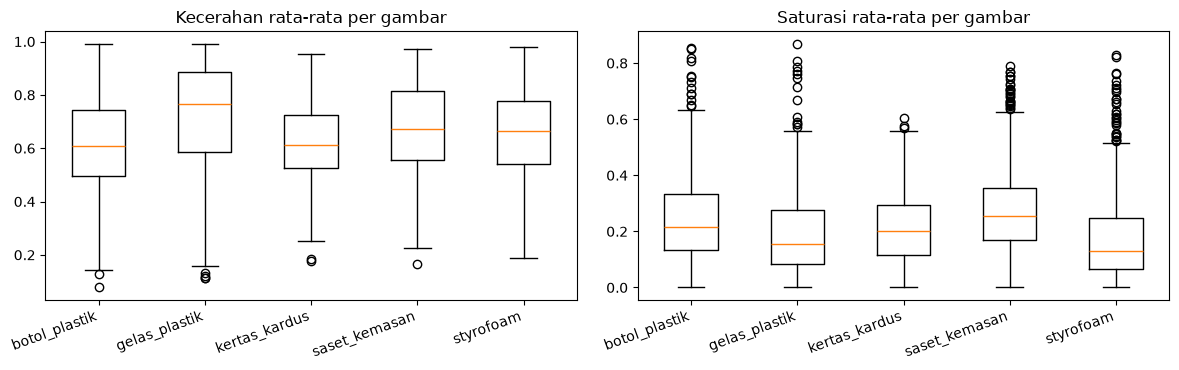

In [7]:
feats = []  # per gambar: mean R, G, B, kecerahan, saturasi (0..1)
for p in all_files:
    with Image.open(p) as im:
        rgb = im.convert("RGB").resize((64, 64))
        hsv = np.asarray(rgb.convert("HSV"), dtype=np.float32) / 255
    rgb = np.asarray(rgb, dtype=np.float32) / 255
    feats.append([*rgb.mean(axis=(0, 1)), hsv[..., 2].mean(), hsv[..., 1].mean()])
feats = np.array(feats)
FEAT_NAMES = ["R", "G", "B", "kecerahan", "saturasi"]

print(f"{'kelas':<15}" + "".join(f"{n:>11}" for n in FEAT_NAMES))
for c in CLASSES:
    print(f"{c:<15}" + "".join(f"{v:>11.3f}" for v in feats[labels == c].mean(axis=0)))

# Nearest centroid dengan 5-fold cross-validation (fitur distandarkan)
rng_np = np.random.default_rng(SEED)
folds = rng_np.permutation(len(feats)) % 5
z = (feats - feats.mean(0)) / feats.std(0)
correct = 0
for k in range(5):
    tr, te = folds != k, folds == k
    cents = np.stack([z[tr & (labels == c)].mean(0) for c in CLASSES])
    pred = np.array(CLASSES)[((z[te][:, None, :] - cents[None]) ** 2).sum(-1).argmin(1)]
    correct += (pred == labels[te]).sum()
chance = max(counts.values()) / total
print()
print(f"akurasi nearest centroid (hanya warna): {correct / len(feats):.1%}  | tebakan kelas terbanyak: {chance:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].boxplot([feats[labels == c, 3] for c in CLASSES], tick_labels=CLASSES)
axes[0].set_title("Kecerahan rata-rata per gambar")
axes[1].boxplot([feats[labels == c, 4] for c in CLASSES], tick_labels=CLASSES)
axes[1].set_title("Saturasi rata-rata per gambar")
for ax in axes:
    plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
plt.tight_layout()
plt.show()

**Temuan:**
- Warna hampir tidak membedakan kelas: nearest centroid dari 5 fitur warna hanya 28,8% (tebakan kelas terbanyak 24,4%) → model tidak bisa mengandalkan warna saja.
- Distribusi kecerahan & saturasi antar kelas sangat tumpang tindih.
- Kecenderungan kecil: `gelas_plastik` paling terang (latar putih katalog), `styrofoam` paling pucat (saturasi rendah), `saset_kemasan` paling berwarna.
- Implikasi: `ColorJitter` aman dipakai dan membantu mengurangi ketergantungan pada latar terang/putih.

## 7. Kandidat label noise per kelas

Spesifikasi menyebut label masih mengandung sedikit *noise*. Tidak ada label "benar" untuk dibandingkan, jadi dipakai pendekatan **k-nearest neighbor di ruang fitur**:
1. Ambil fitur tiap gambar dari ResNet-18 pretrained ImageNet (tanpa head, dibekukan) → vektor 512 dimensi.
2. Untuk tiap gambar, cari 10 tetangga terdekat (cosine similarity).
3. **Kandidat noise** = gambar yang < 30% tetangganya berlabel sama **dan** mayoritas tetangganya dari satu kelas lain.

Catatan:
- Hasilnya **kandidat**, bukan vonis: perlu dicek manual. Gambar yang memang ambigu sesuai definisi kelas (mis. gelas kertas → `kertas_kardus`) bisa ikut tertandai.
- Daftar kandidat disimpan ke `data/label_noise_candidates.csv` (di-ignore git) untuk dicek manual.

kelas            total  kandidat      %   -> mayoritas tetangga
botol_plastik      523        20   3.8%   gelas_plastik: 4, kertas_kardus: 1, saset_kemasan: 10, styrofoam: 5
gelas_plastik      521        23   4.4%   botol_plastik: 9, saset_kemasan: 9, styrofoam: 5
kertas_kardus      365        56  15.3%   botol_plastik: 2, gelas_plastik: 11, saset_kemasan: 17, styrofoam: 26
saset_kemasan      673        33   4.9%   botol_plastik: 6, gelas_plastik: 10, kertas_kardus: 4, styrofoam: 13
styrofoam          671        26   3.9%   botol_plastik: 10, gelas_plastik: 4, kertas_kardus: 3, saset_kemasan: 9
TOTAL             2753       158   5.7%

daftar kandidat: data\label_noise_candidates.csv


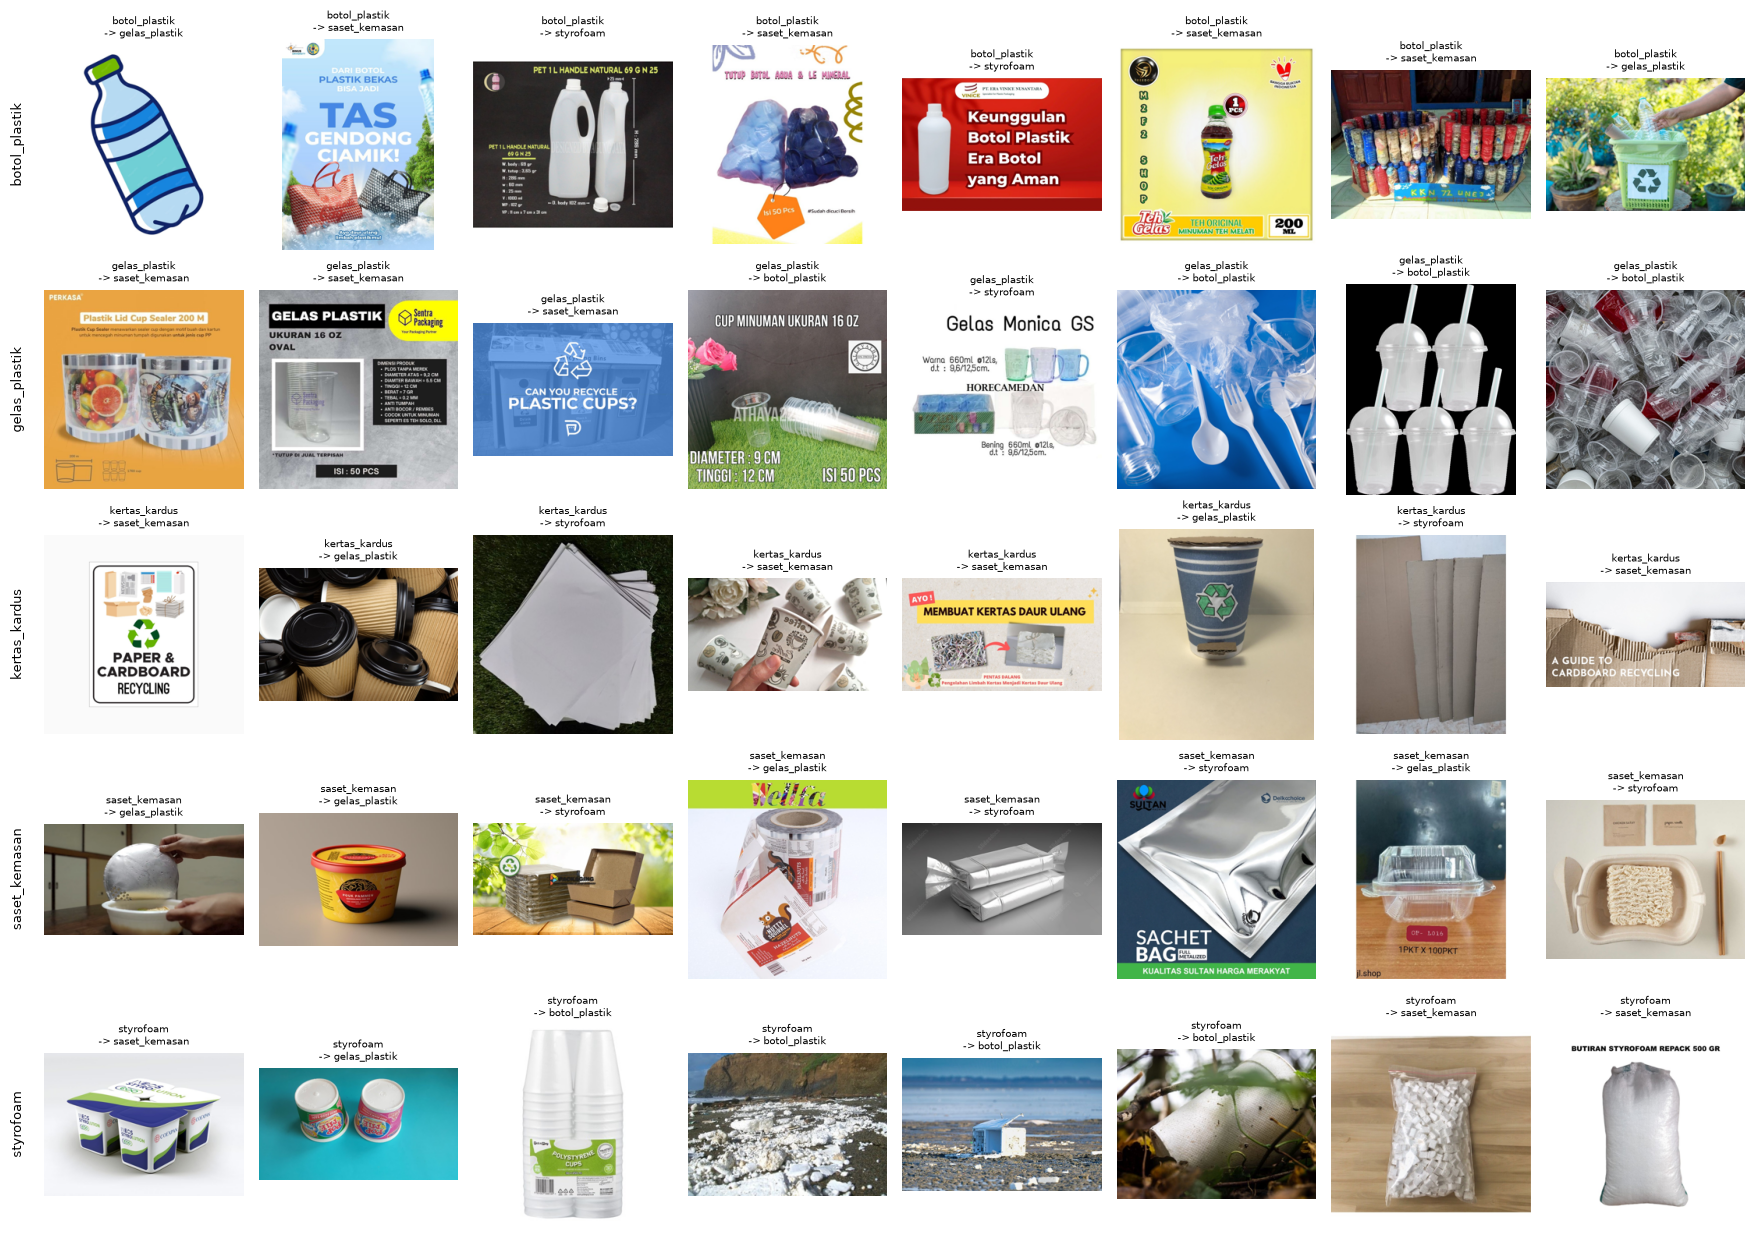

In [8]:
K_NEIGHBORS = 10
MIN_SAME = 0.3  # di bawah ini dianggap kandidat noise
device = "cuda" if torch.cuda.is_available() else "cpu"

# 1) Ekstraksi fitur dengan backbone pretrained (bobot ImageNet diunduh sekali ke cache torch)
backbone = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
backbone.fc = torch.nn.Identity()
backbone.eval().to(device)
feat_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

emb = []
with torch.no_grad():
    for start in range(0, len(all_files), 64):
        batch = []
        for p in all_files[start:start + 64]:
            with Image.open(p) as im:
                batch.append(feat_tf(im.convert("RGB")))
        emb.append(backbone(torch.stack(batch).to(device)).cpu())
emb = torch.nn.functional.normalize(torch.cat(emb), dim=1).numpy()  # [N, 512], panjang 1
del backbone
torch.cuda.empty_cache()

# 2) 10 tetangga terdekat per gambar (cosine similarity = dot product vektor ternormalisasi)
sim = emb @ emb.T
np.fill_diagonal(sim, -1)  # jangan hitung diri sendiri
nn_idx = np.argsort(-sim, axis=1)[:, :K_NEIGHBORS]
nn_labels = labels[nn_idx]  # [N, K]

same_frac = (nn_labels == labels[:, None]).mean(axis=1)
majority, majority_frac = [], []
for row in nn_labels:
    vals, cnts = np.unique(row, return_counts=True)
    majority.append(vals[cnts.argmax()])
    majority_frac.append(cnts.max() / K_NEIGHBORS)
majority, majority_frac = np.array(majority), np.array(majority_frac)

# 3) Kandidat noise
is_cand = (same_frac < MIN_SAME) & (majority != labels)
cand_idx = np.where(is_cand)[0]

print(f"{'kelas':<15} {'total':>6} {'kandidat':>9} {'%':>6}   -> mayoritas tetangga")
for c in CLASSES:
    m = labels == c
    to = {o: int((is_cand & m & (majority == o)).sum()) for o in CLASSES if o != c}
    to_str = ", ".join(f"{o}: {n}" for o, n in to.items() if n)
    print(f"{c:<15} {m.sum():>6} {(is_cand & m).sum():>9} {(is_cand & m).mean() / m.mean():>6.1%}   {to_str}")
print(f"{'TOTAL':<15} {len(labels):>6} {is_cand.sum():>9} {is_cand.mean():>6.1%}")

# Simpan daftar kandidat untuk dicek manual
out_csv = ROOT / "data" / "label_noise_candidates.csv"
out_csv.parent.mkdir(exist_ok=True)
with open(out_csv, "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["file", "label", "mayoritas_tetangga", "frac_label_sama", "frac_mayoritas"])
    for i in cand_idx[np.argsort(same_frac[cand_idx])]:
        w.writerow([all_files[i].relative_to(ROOT).as_posix(), labels[i], majority[i],
                    f"{same_frac[i]:.1f}", f"{majority_frac[i]:.1f}"])
print(f"\ndaftar kandidat: {out_csv.relative_to(ROOT)}")

# Tampilkan kandidat paling kuat per kelas (maks 8)
N_SHOW = 8
fig, axes = plt.subplots(len(CLASSES), N_SHOW, figsize=(2.2 * N_SHOW, 2.5 * len(CLASSES)))
for r, c in enumerate(CLASSES):
    idx_c = cand_idx[labels[cand_idx] == c]
    idx_c = idx_c[np.argsort(same_frac[idx_c])][:N_SHOW]
    for col in range(N_SHOW):
        ax = axes[r, col]
        ax.axis("off")
        if col < len(idx_c):
            i = idx_c[col]
            ax.imshow(thumb(all_files[i]))
            ax.set_title(f"{labels[i]}\n-> {majority[i]}", fontsize=7)
    axes[r, 0].text(-0.1, 0.5, c, transform=axes[r, 0].transAxes, rotation=90,
                    ha="right", va="center", fontsize=9)
plt.tight_layout()
plt.show()

**Temuan (hasil cek visual semua kandidat):**

| Kelas | Kandidat kNN | Salah label | Ambigu | Salah label (% kelas) |
|---|---|---|---|---|
| `botol_plastik` | 20 | 1 | 1 | 0.2% |
| `gelas_plastik` | 23 | 3 | 4 | 0.6% |
| `kertas_kardus` | 56 | 0 | 3 | 0.0% |
| `saset_kemasan` | 33 | 7 | 4 | 1.0% |
| `styrofoam` | 26 | 2 | 2 | 0.3% |
| **Total** | 158 | 13 | 14 | 0.5% |

- Dari 158 kandidat kNN, hanya ±13 yang jelas salah label; sisanya kebanyakan gambar **atipikal tapi labelnya benar** (ikon, banner, katalog) atau **ambigu sesuai definisi** (gelas kertas di `kertas_kardus`).
- `kertas_kardus` paling banyak kandidat (56) tapi praktis tidak ada yang salah label → kelas ini memang mirip `styrofoam`/`gelas_plastik` secara visual (gelas kertas, kertas putih).
- `saset_kemasan` paling banyak salah label (wadah kaku: mangkuk, kotak, cup).
- Batasan: penilaian dari thumbnail, subjektif; gambar salah label yang mirip satu sama lain (mis. beberapa rol film sealer di `gelas_plastik`) saling "mendukung" sebagai tetangga sehingga bisa lolos → angka sebenarnya bisa sedikit lebih tinggi.
- Hasil cek per gambar: `data/label_noise_review.csv` (kolom `cek_visual`: salah_label / ambigu / benar).

**Keputusan:** data dibiarkan apa adanya (tidak ada gambar yang dibuang atau di-relabel); noise ±0,5% ditangani dengan `label_smoothing` saat training.
Membuang 9 gambar salah label dari `my_train` disimpan sebagai eksperimen terpisah bila confusion matrix menunjukkan `saset_kemasan` sering tertukar dengan wadah kaku. `my_val` tidak dibersihkan supaya tetap mewakili validation set rahasia.